# Exploratory analysis and preprocessing

**Purpose:** Inspect development data only; verify missingness, skew, imbalance and associations before fitting classifiers.

Requires the complete project folder and dependencies from `requirements.txt`; see README.md for local/Colab/Kaggle setup. Matching saved artifacts are reused. Use `force=True` in the phase cell to recompute. Outputs must remain visible when saving.

In [1]:
from pathlib import Path
import os, sys
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ.setdefault(name, '2')
candidates = [Path.cwd(), *Path.cwd().parents,
              Path('/content/hospital-readmission'), Path('/kaggle/working/hospital-readmission')]
ROOT = next((p for p in candidates if (p / 'config.json').exists() and (p / 'readmission').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Extract the full project and set the working directory to hospital-readmission first. See README.md.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, JSON
from readmission.common import read_json
from readmission.pipeline import run_phase
pd.set_option('display.max_columns', 30)
print('Project:', ROOT.name)


Project: hospital-readmission


In [2]:
run_phase('eda')

Phase data: reusing verified matching artifacts.


Phase eda: reusing verified matching artifacts.


In [3]:
display(pd.read_csv(ROOT / 'artifacts/tables/missingness.csv').head(15))

,feature,missing_fraction
0,weight,0.968074
1,medical_specialty,0.489610
2,payer_code,0.395944
3,race,0.022524
4,diag_3,0.013927
5,diag_2,0.003553
6,diag_1,0.000251
7,admission_source_id,0.000000
8,discharge_disposition_id,0.000000
9,time_in_hospital,0.000000


In [4]:
display(pd.read_csv(ROOT / 'artifacts/tables/numeric_summary.csv'))

,Unnamed: 0,count,mean,std,min,1%,25%,50%,75%,99%,max
0,time_in_hospital,59670.0,4.364454,2.952804,1.0,1.0,2.0,4.0,6.0,13.0,14.0
1,num_lab_procedures,59670.0,42.866583,19.568948,1.0,1.0,31.0,44.0,57.0,84.0,132.0
2,num_procedures,59670.0,1.329160,1.702160,0.0,0.0,0.0,1.0,2.0,6.0,6.0
3,num_medications,59670.0,15.968762,8.080817,1.0,3.0,10.0,15.0,20.0,43.0,79.0
4,number_outpatient,59670.0,0.365913,1.251955,0.0,0.0,0.0,0.0,0.0,5.0,40.0
5,number_emergency,59670.0,0.204961,1.031906,0.0,0.0,0.0,0.0,0.0,3.0,76.0
6,number_inpatient,59670.0,0.637205,1.277435,0.0,0.0,0.0,0.0,1.0,6.0,21.0
7,number_diagnoses,59670.0,7.411111,1.936090,1.0,2.0,6.0,8.0,9.0,9.0,16.0


In [5]:
display(JSON(read_json('artifacts/preprocessing_audit.json')))

<IPython.core.display.JSON object>

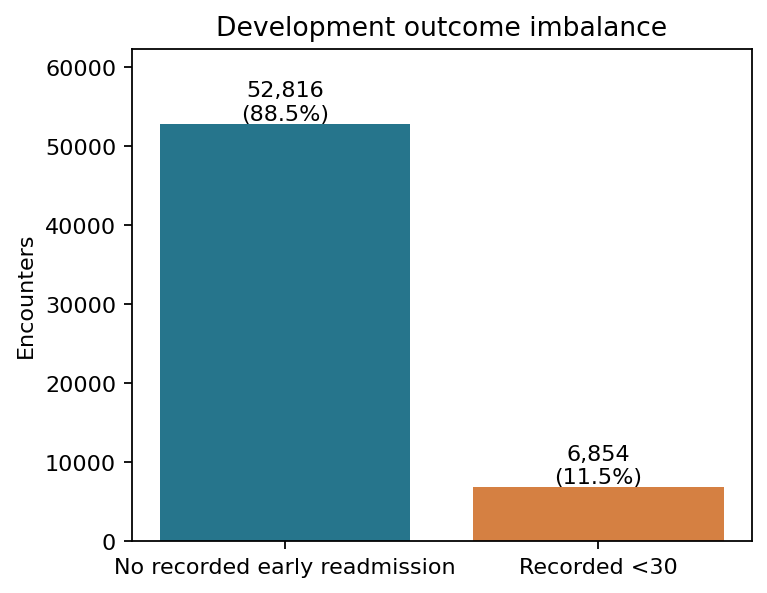

In [6]:
display(Image(filename=str(ROOT / 'artifacts/figures/class_balance.png'), width=1000))

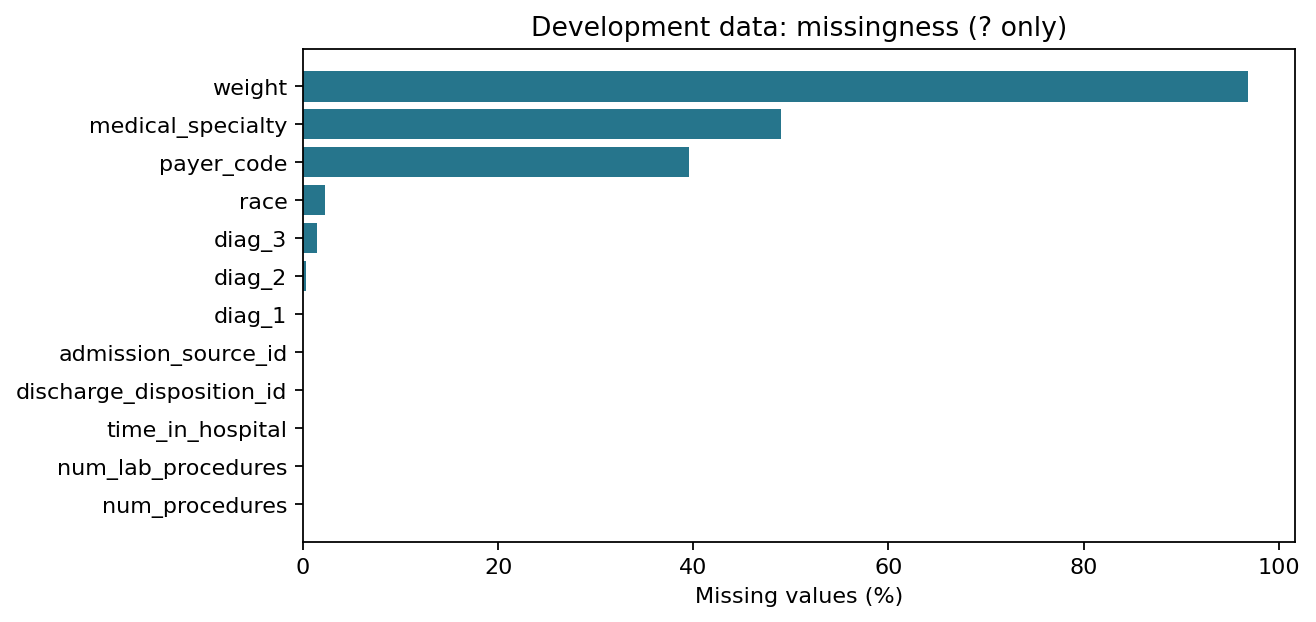

In [7]:
display(Image(filename=str(ROOT / 'artifacts/figures/missingness.png'), width=1000))

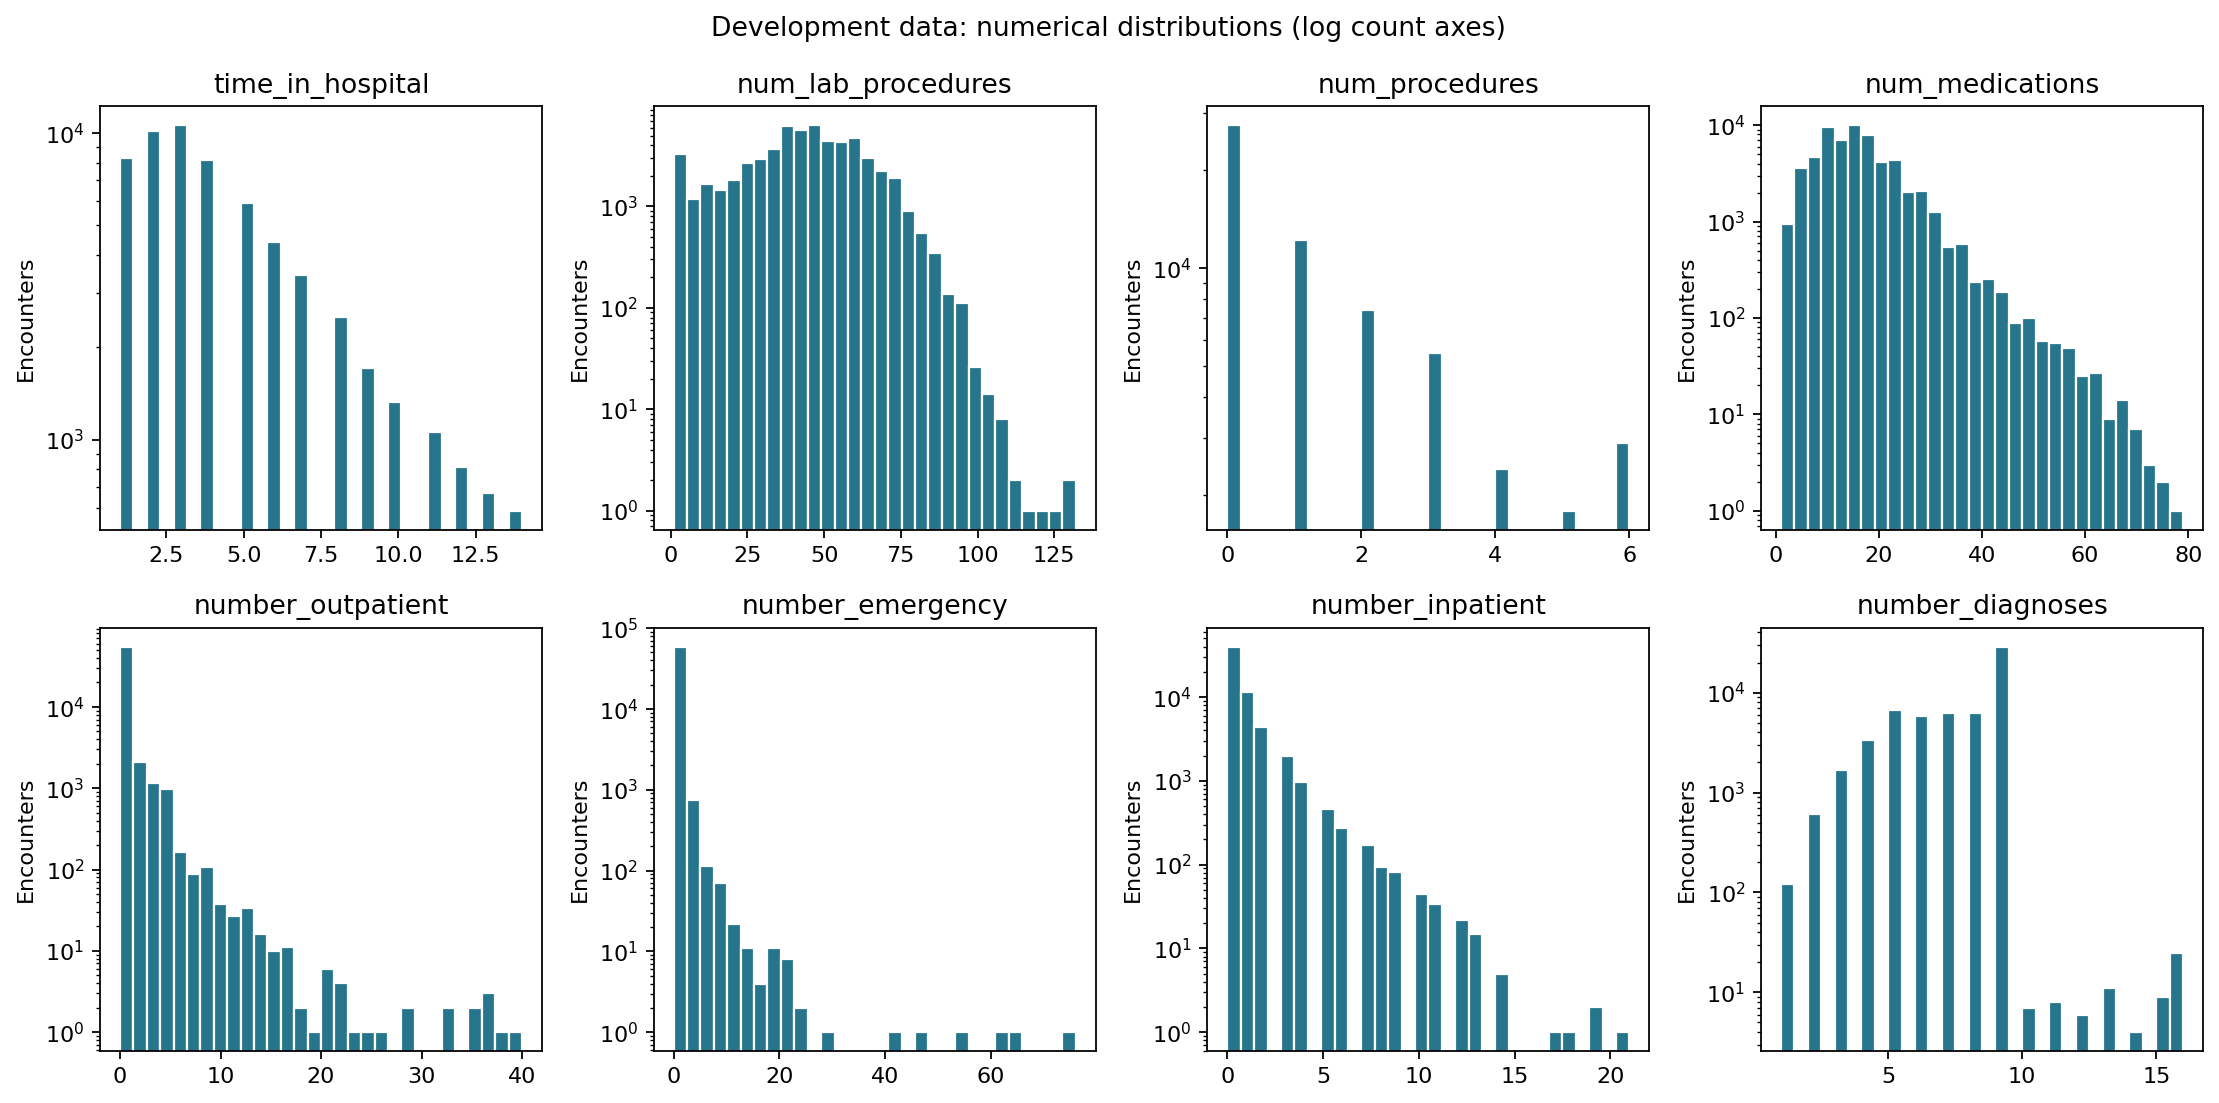

In [8]:
display(Image(filename=str(ROOT / 'artifacts/figures/numeric_distributions.png'), width=1000))

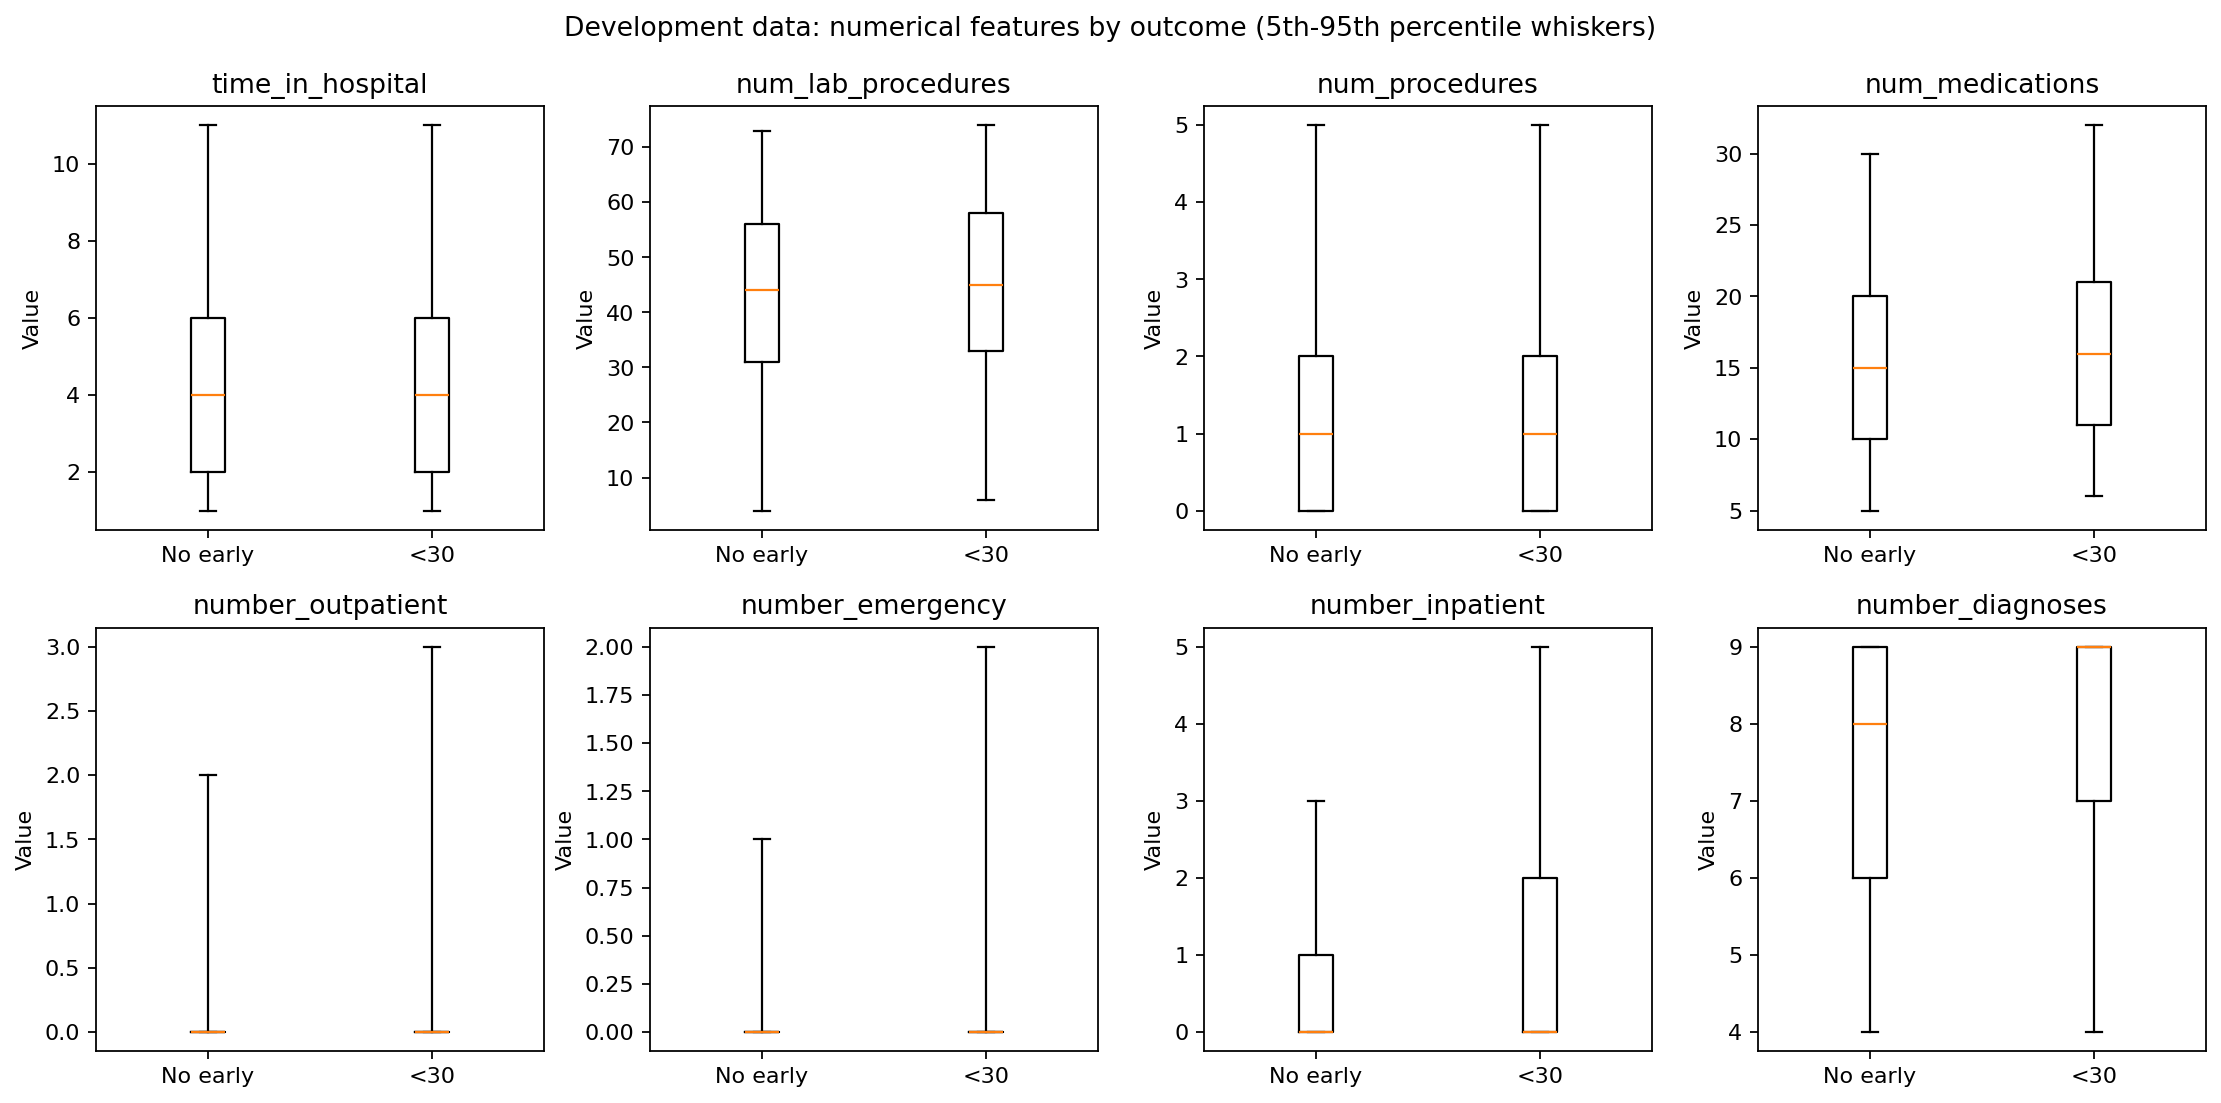

In [9]:
display(Image(filename=str(ROOT / 'artifacts/figures/numeric_by_outcome.png'), width=1000))

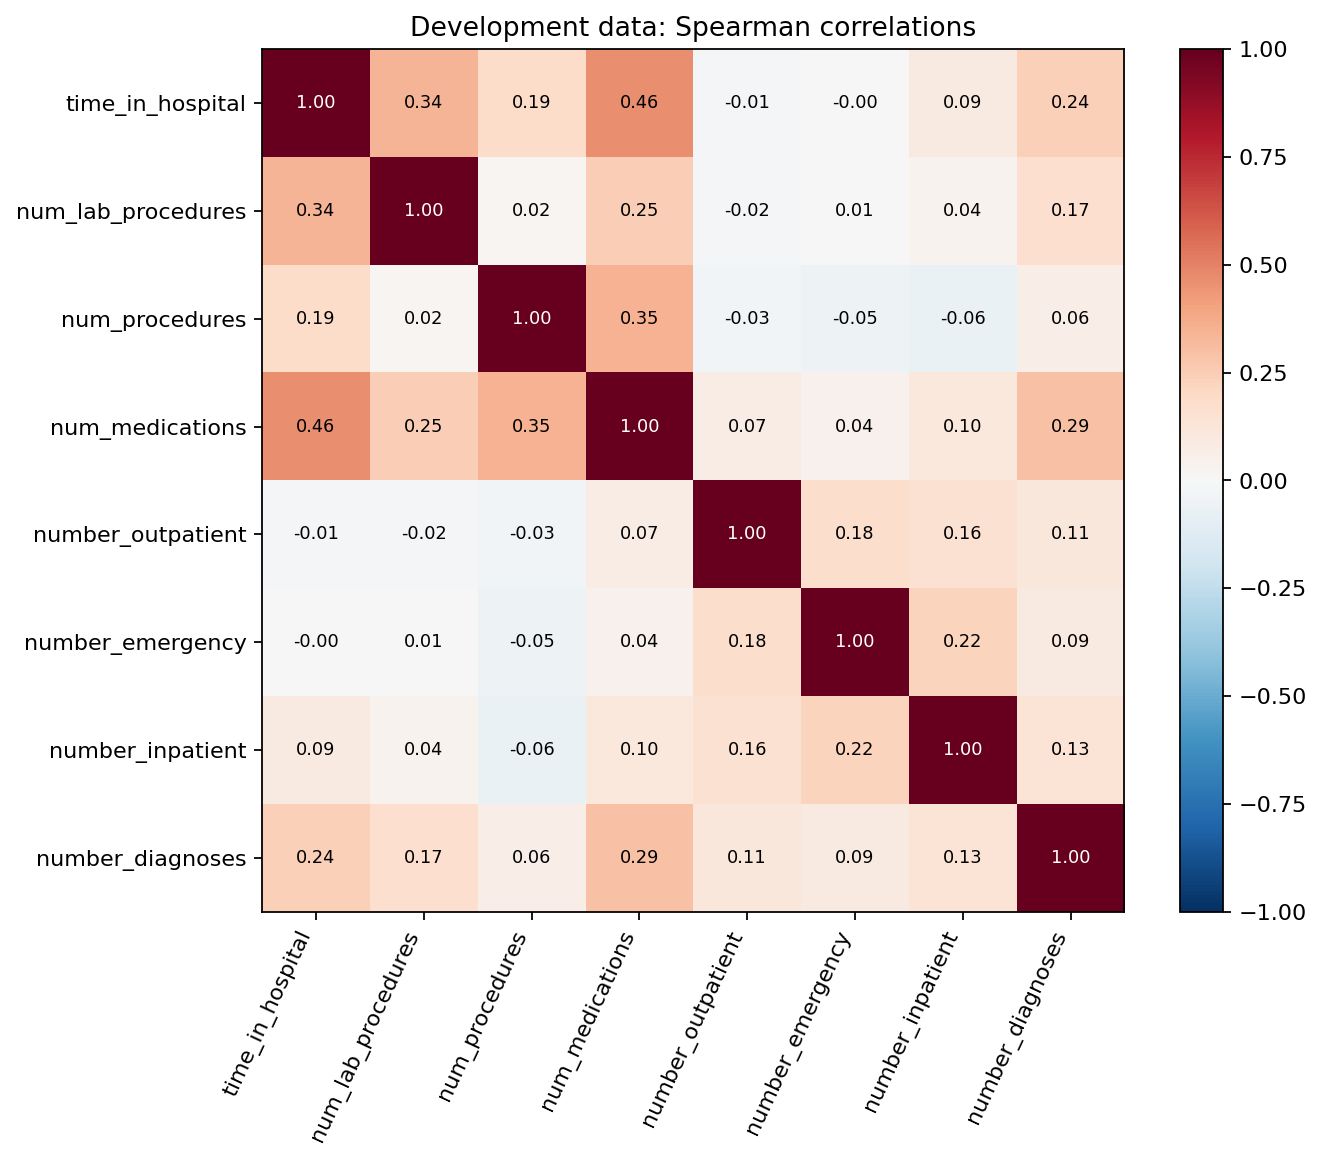

In [10]:
display(Image(filename=str(ROOT / 'artifacts/figures/correlations.png'), width=1000))

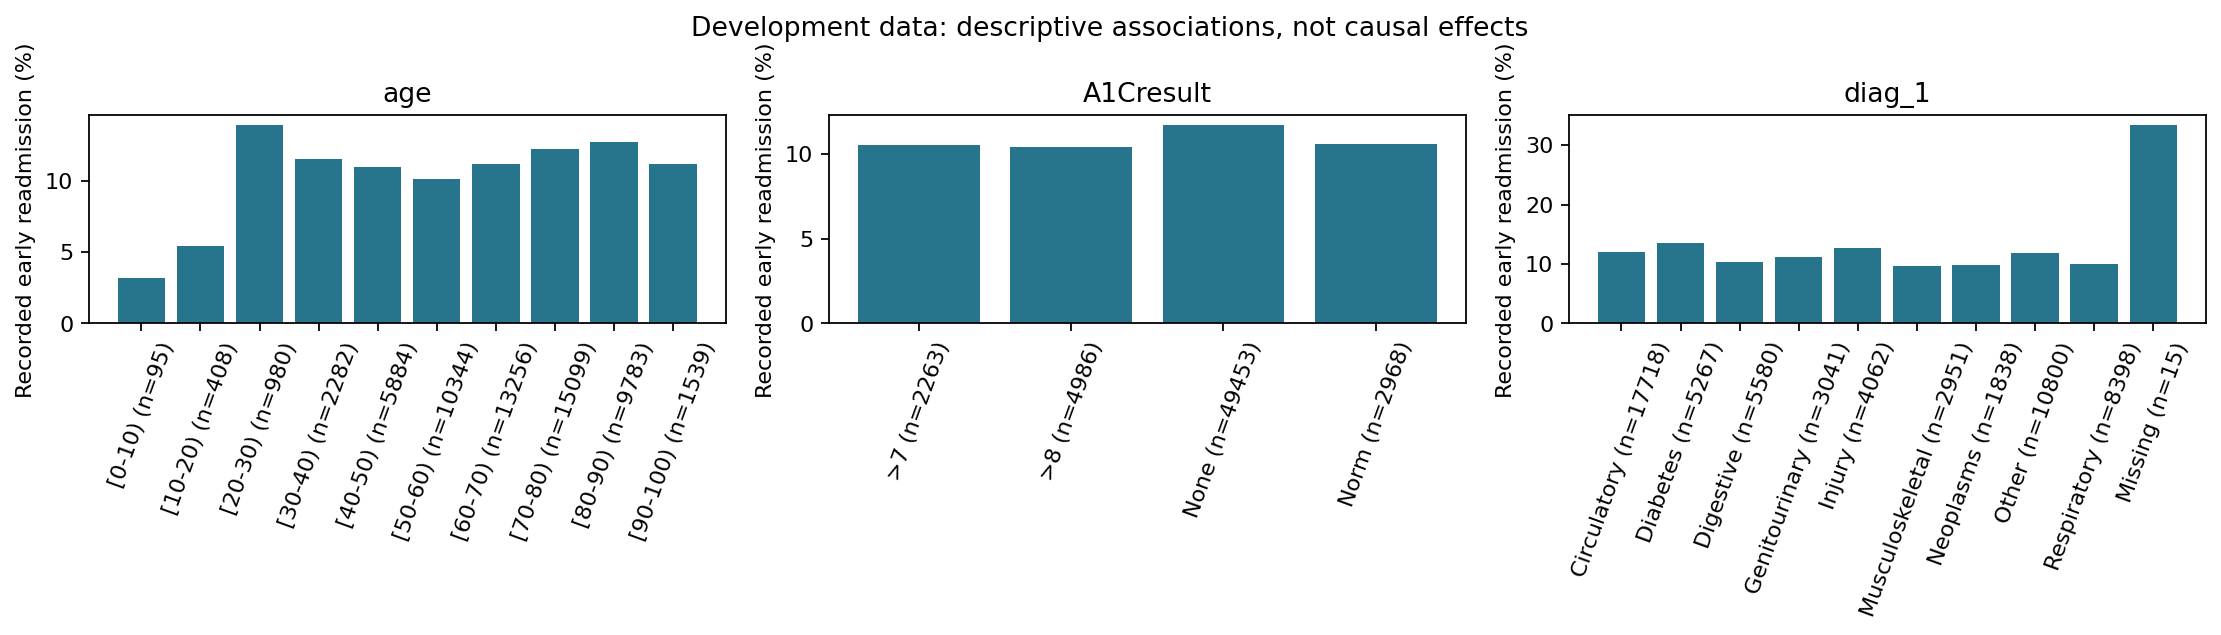

In [11]:
display(Image(filename=str(ROOT / 'artifacts/figures/categorical_outcomes.png'), width=1000))

## Team interpretation prompts

Explain the distinction between missing tests and tests not performed, and discuss associations without claiming causation.

Write your own report discussion after checking the evidence.